DRIVEDECISION AI — INITIALIZING

[1/12] Downloading UCI Car Evaluation Dataset...
Dataset downloaded successfully!
Dataset shape: (1728, 7)
  buying  maint doors persons lug_boot safety  class
0  vhigh  vhigh     2       2    small    low  unacc
1  vhigh  vhigh     2       2    small    med  unacc
2  vhigh  vhigh     2       2    small   high  unacc
3  vhigh  vhigh     2       2      med    low  unacc
4  vhigh  vhigh     2       2      med    med  unacc

[2/12] Cleaning dataset...
Clean dataset shape: (1728, 7)
Missing values: 0

Class distribution:
class
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64

[3/12] Dataset analysis...

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   perso

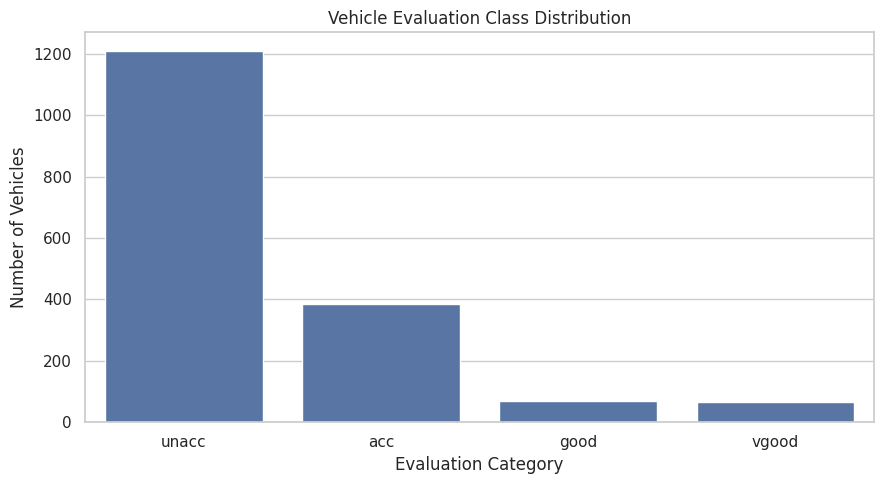

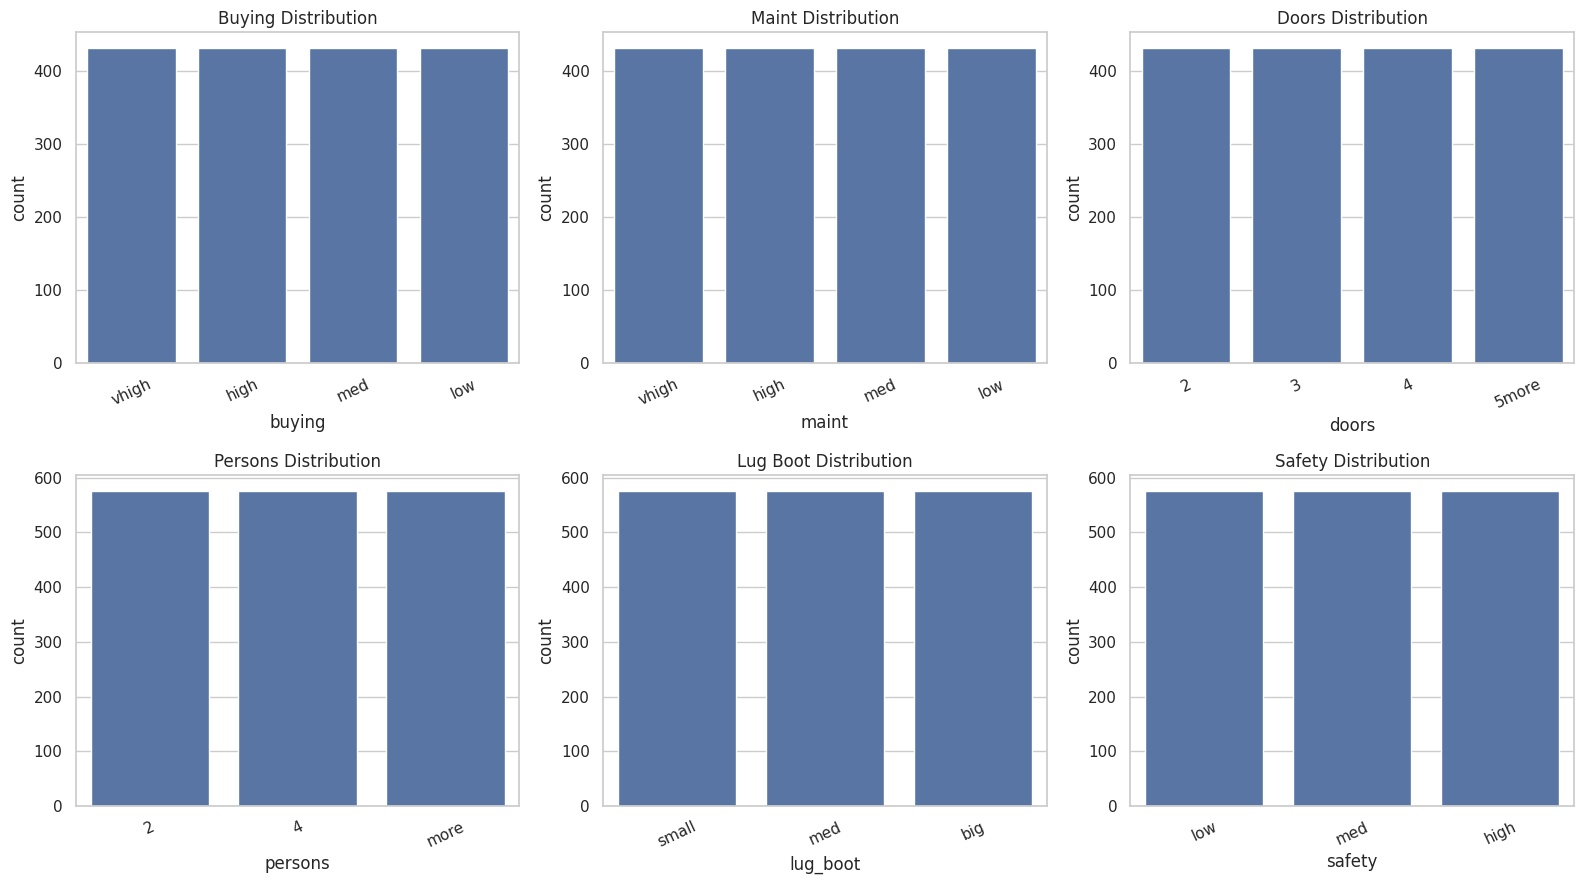

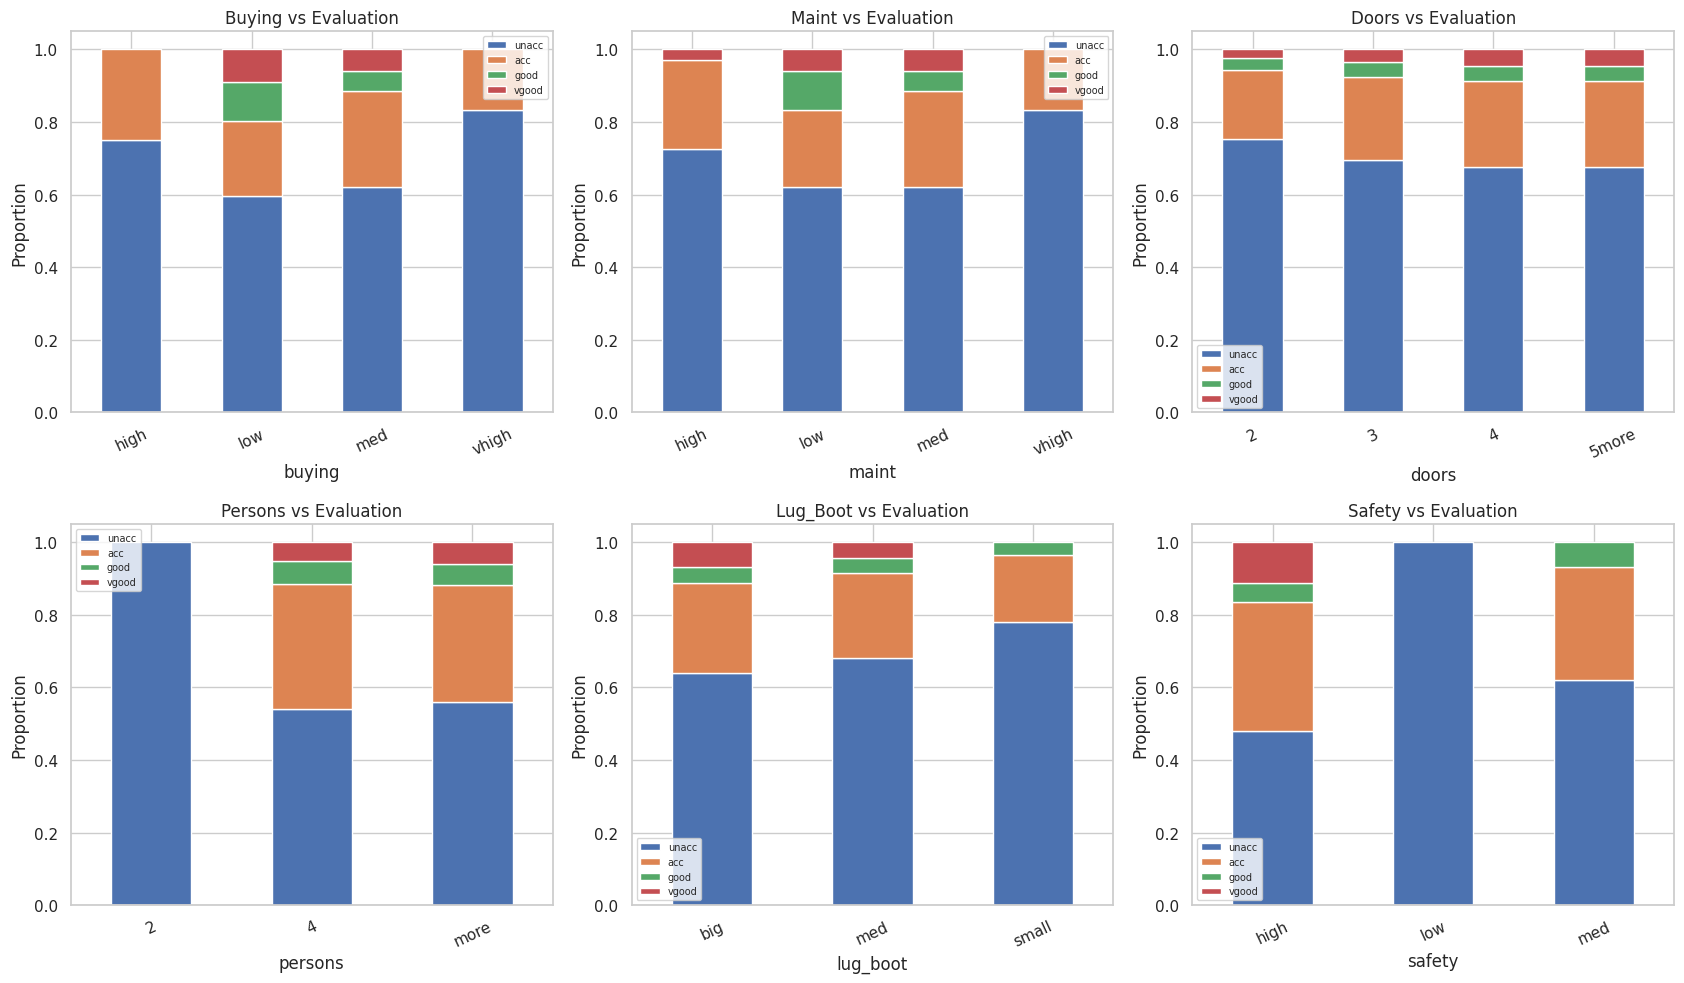


[5/12] Preparing machine learning features...
Features: ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']
Target: class
Target categories: ['acc', 'good', 'unacc', 'vgood']

[6/12] Splitting data...
Training records: 1382
Testing records: 346

[7/12] Creating preprocessing pipeline...

[8/12] Training multiple ML models...
Dummy Baseline completed.
Decision Tree completed.
Random Forest completed.
Logistic Regression completed.

MODEL COMPARISON
              Model  Accuracy  Precision_Macro  Recall_Macro  F1_Macro  F1_Weighted
      Random Forest    0.9740           0.9781        0.9490    0.9628       0.9741
      Decision Tree    0.9653           0.9270        0.9379    0.9273       0.9656
Logistic Regression    0.8873           0.7661        0.9331    0.8315       0.8932
     Dummy Baseline    0.6994           0.1749        0.2500    0.2058       0.5757

[9/12] Performing 5-fold cross-validation...

CROSS VALIDATION RESULTS
              Model  CV_Accuracy_Mean  CV_Acc

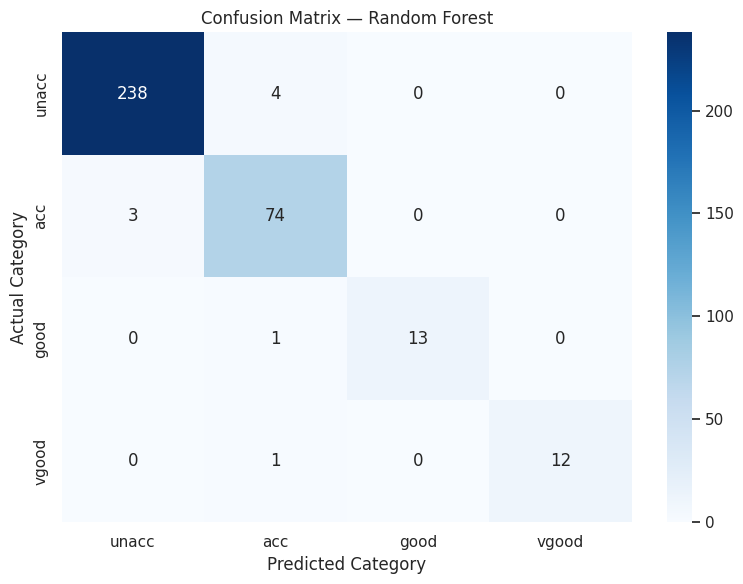


[11/12] Explaining model decisions...

FEATURE IMPORTANCE
                    Feature  Importance
     categorical__persons_2    0.377794
    categorical__safety_low    0.258862
     categorical__maint_low    0.124425
   categorical__maint_vhigh    0.076957
  categorical__buying_vhigh    0.064733
     categorical__maint_med    0.045032
   categorical__buying_high    0.042359
categorical__lug_boot_small    0.009839
    categorical__buying_low    0.000000
    categorical__maint_high    0.000000
    categorical__buying_med    0.000000
       categorical__doors_2    0.000000
       categorical__doors_3    0.000000
   categorical__doors_5more    0.000000
       categorical__doors_4    0.000000
     categorical__persons_4    0.000000
  categorical__persons_more    0.000000
  categorical__lug_boot_med    0.000000
  categorical__lug_boot_big    0.000000
   categorical__safety_high    0.000000


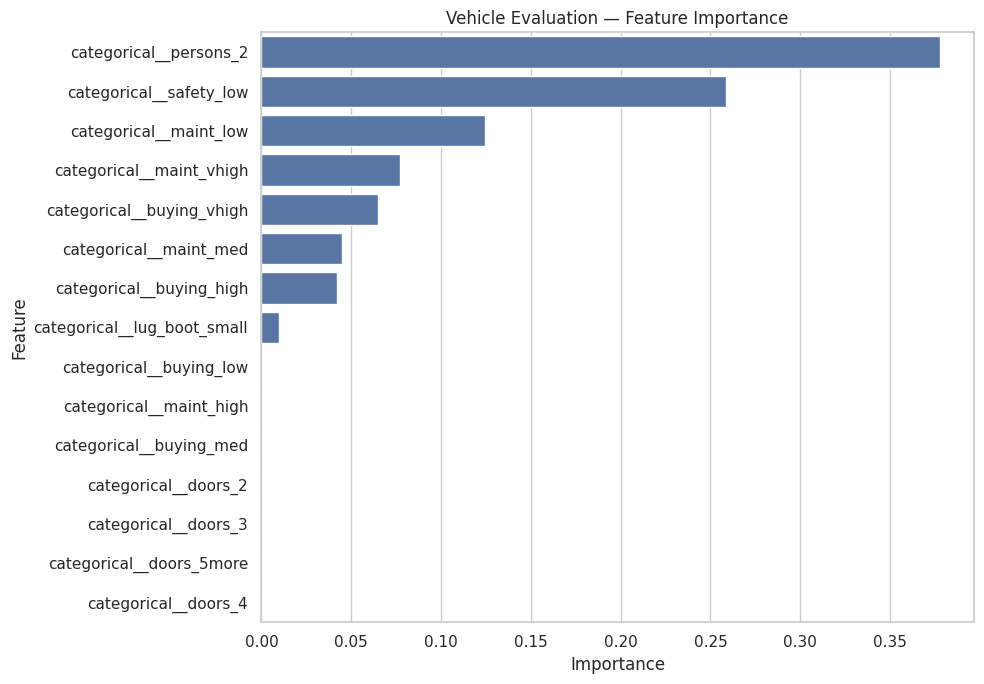

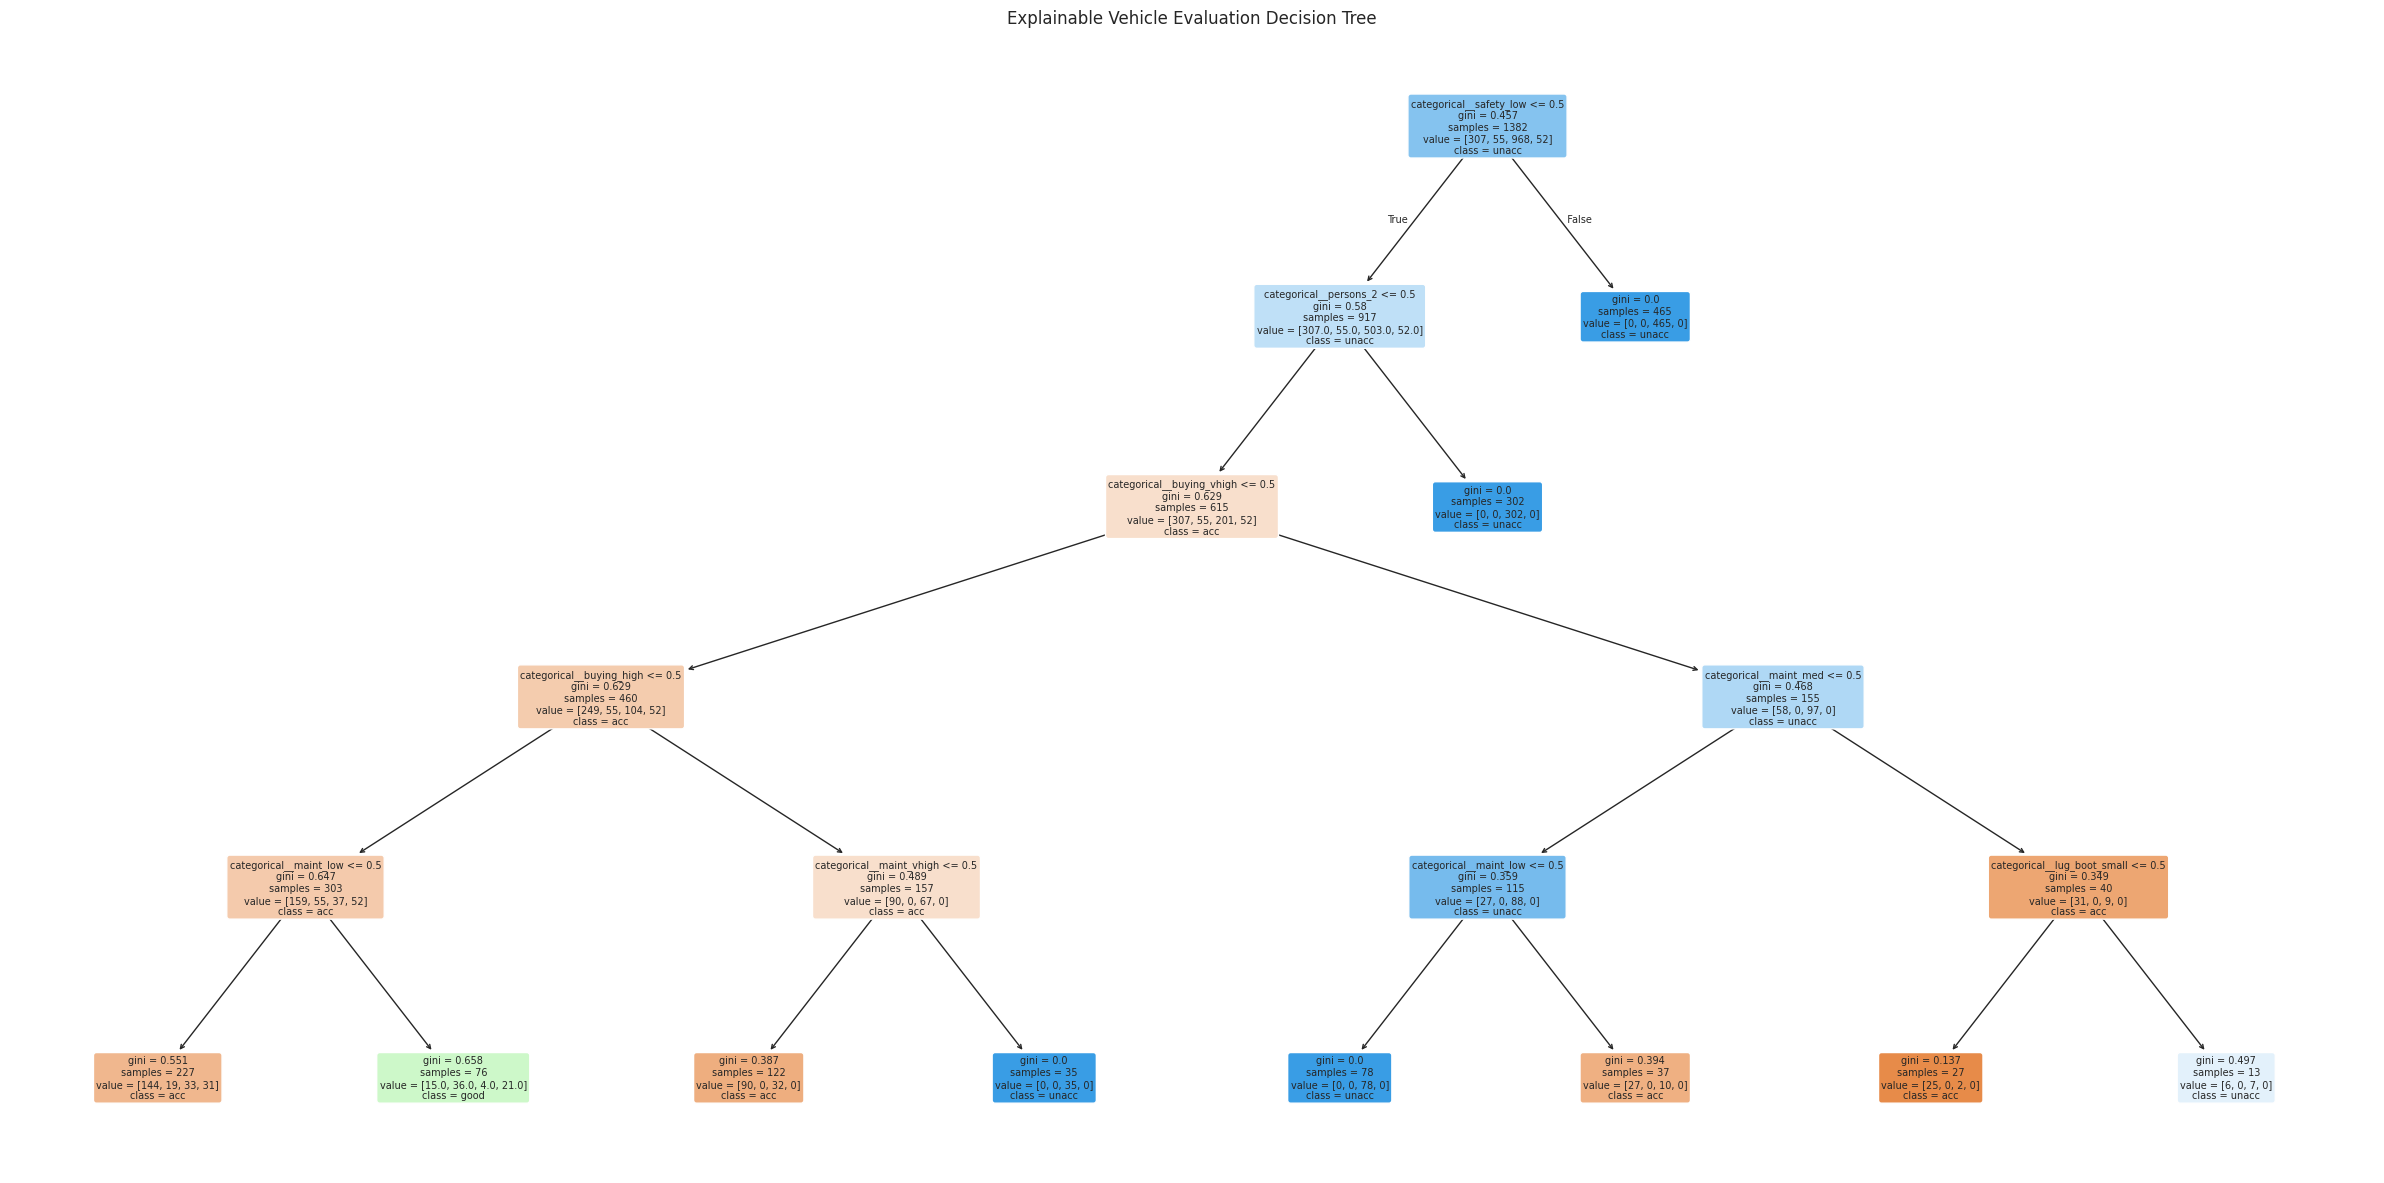


DECISION TREE RULES
|--- categorical__safety_low <= 0.50
|   |--- categorical__persons_2 <= 0.50
|   |   |--- categorical__buying_vhigh <= 0.50
|   |   |   |--- categorical__buying_high <= 0.50
|   |   |   |   |--- categorical__maint_low <= 0.50
|   |   |   |   |   |--- class: acc
|   |   |   |   |--- categorical__maint_low >  0.50
|   |   |   |   |   |--- class: good
|   |   |   |--- categorical__buying_high >  0.50
|   |   |   |   |--- categorical__maint_vhigh <= 0.50
|   |   |   |   |   |--- class: acc
|   |   |   |   |--- categorical__maint_vhigh >  0.50
|   |   |   |   |   |--- class: unacc
|   |   |--- categorical__buying_vhigh >  0.50
|   |   |   |--- categorical__maint_med <= 0.50
|   |   |   |   |--- categorical__maint_low <= 0.50
|   |   |   |   |   |--- class: unacc
|   |   |   |   |--- categorical__maint_low >  0.50
|   |   |   |   |   |--- class: acc
|   |   |   |--- categorical__maint_med >  0.50
|   |   |   |   |--- categorical__lug_boot_small <= 0.50
|   |   |   |   | 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


DriveDecision AI is ready for GitHub preparation!


In [1]:

# ================================================================

import os
import sys
import json
import zipfile
import sqlite3
import warnings
import subprocess
import requests
import shutil
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from io import BytesIO

warnings.filterwarnings("ignore")

# -------------------- 1. INSTALLATION ----------------------------

print("=" * 65)
print("DRIVEDECISION AI — INITIALIZING")
print("=" * 65)

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "scikit-learn", "seaborn", "joblib"
])

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

PROJECT = Path("/content/DriveDecision-AI")
for folder in [
    "data", "outputs/visualizations",
    "outputs/reports", "models"
]:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)

# -------------------- 2. DATA COLLECTION ------------------------

print("\n[1/12] Downloading UCI Car Evaluation Dataset...")

DATA_URL = (
    "https://archive.ics.uci.edu/static/public/19/"
    "car+evaluation.zip"
)

response = requests.get(DATA_URL, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(BytesIO(response.content)) as z:
    data_file = next(
        name for name in z.namelist()
        if name.lower().endswith("car.data")
    )
    with z.open(data_file) as f:
        df = pd.read_csv(f, header=None)

columns = [
    "buying", "maint", "doors",
    "persons", "lug_boot", "safety", "class"
]
df.columns = columns

df.to_csv(PROJECT / "data" / "car_evaluation_raw.csv", index=False)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

# -------------------- 3. DATA CLEANING --------------------------

print("\n[2/12] Cleaning dataset...")

df = df.drop_duplicates().copy()

# Convert categorical values into consistent strings
for col in columns:
    df[col] = df[col].astype(str).str.strip().str.lower()

# Remove invalid or missing records
df = df.replace({"?": np.nan, "nan": np.nan})
df = df.dropna(subset=columns)

valid_values = {
    "buying": ["vhigh", "high", "med", "low"],
    "maint": ["vhigh", "high", "med", "low"],
    "doors": ["2", "3", "4", "5more"],
    "persons": ["2", "4", "more"],
    "lug_boot": ["small", "med", "big"],
    "safety": ["low", "med", "high"],
    "class": ["unacc", "acc", "good", "vgood"]
}

for col, allowed in valid_values.items():
    df = df[df[col].isin(allowed)]

df = df.reset_index(drop=True)

print("Clean dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("\nClass distribution:")
print(df["class"].value_counts())

df.to_csv(PROJECT / "data" / "car_evaluation_clean.csv", index=False)

# -------------------- 4. DATA UNDERSTANDING ---------------------

print("\n[3/12] Dataset analysis...")

print("\nDataset information:")
print(df.info())

print("\nStatistical summary:")
print(df.describe(include="all").T)

print("\nUnique values:")
for col in columns:
    print(col, ":", sorted(df[col].unique()))

# -------------------- 5. EDA VISUALIZATIONS ---------------------

print("\n[4/12] Creating visualizations...")

sns.set_theme(style="whitegrid")

# Class distribution
plt.figure(figsize=(9, 5))
order = ["unacc", "acc", "good", "vgood"]
sns.countplot(data=df, x="class", order=order)
plt.title("Vehicle Evaluation Class Distribution")
plt.xlabel("Evaluation Category")
plt.ylabel("Number of Vehicles")
plt.tight_layout()
plt.savefig(
    PROJECT / "outputs/visualizations/class_distribution.png",
    dpi=200
)
plt.show()

# Feature distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
features = columns[:-1]

for ax, col in zip(axes.flatten(), features):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"{col.replace('_', ' ').title()} Distribution")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(
    PROJECT / "outputs/visualizations/feature_distributions.png",
    dpi=200
)
plt.show()

# Feature versus class
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, col in zip(axes.flatten(), features):
    cross = pd.crosstab(df[col], df["class"], normalize="index")
    cross = cross.reindex(columns=order, fill_value=0)
    cross.plot(kind="bar", stacked=True, ax=ax)
    ax.set_title(f"{col.title()} vs Evaluation")
    ax.set_ylabel("Proportion")
    ax.tick_params(axis="x", rotation=25)
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig(
    PROJECT / "outputs/visualizations/feature_class_relationships.png",
    dpi=200
)
plt.show()

# -------------------- 6. FEATURE / TARGET DEFINITION ------------

print("\n[5/12] Preparing machine learning features...")

X = df[features].copy()
y = df["class"].copy()

print("Features:", list(X.columns))
print("Target:", "class")
print("Target categories:", sorted(y.unique()))

# -------------------- 7. TRAIN / TEST SPLIT ---------------------

print("\n[6/12] Splitting data...")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# -------------------- 8. PREPROCESSING PIPELINE ------------------

print("\n[7/12] Creating preprocessing pipeline...")

# Compatibility across scikit-learn versions
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", encoder)
            ]),
            features
        )
    ],
    remainder="drop"
)

# -------------------- 9. MODEL TRAINING -------------------------

print("\n[8/12] Training multiple ML models...")

models = {
    "Dummy Baseline": DummyClassifier(strategy="most_frequent"),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_split=4,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

pipelines = {}
results = []
predictions = {}

for name, model in models.items():

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)
    predictions[name] = pred
    pipelines[name] = pipe

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_Macro": precision_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "Recall_Macro": recall_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "F1_Macro": f1_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "F1_Weighted": f1_score(
            y_test, pred, average="weighted", zero_division=0
        )
    })

    print(f"{name} completed.")

results_df = pd.DataFrame(results).sort_values(
    "F1_Macro", ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON")
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    PROJECT / "outputs/reports/model_comparison.csv",
    index=False
)

# -------------------- 10. CROSS VALIDATION ---------------------

print("\n[9/12] Performing 5-fold cross-validation...")

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_rows = []

for name, model in models.items():

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "f1_macro"],
        n_jobs=-1
    )

    cv_rows.append({
        "Model": name,
        "CV_Accuracy_Mean": scores["test_accuracy"].mean(),
        "CV_Accuracy_Std": scores["test_accuracy"].std(),
        "CV_Macro_F1_Mean": scores["test_f1_macro"].mean(),
        "CV_Macro_F1_Std": scores["test_f1_macro"].std()
    })

cv_df = pd.DataFrame(cv_rows)
print("\nCROSS VALIDATION RESULTS")
print(cv_df.round(4).to_string(index=False))

cv_df.to_csv(
    PROJECT / "outputs/reports/cross_validation.csv",
    index=False
)

# Select model based on holdout macro F1
best_name = results_df.iloc[0]["Model"]
best_model = pipelines[best_name]
best_predictions = predictions[best_name]

print("\nSELECTED MODEL:", best_name)

# -------------------- 11. CLASSIFICATION REPORT -----------------

print("\n[10/12] Generating detailed evaluation...")

report = classification_report(
    y_test,
    best_predictions,
    labels=order,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()
print(report_df.round(4))

report_df.to_csv(
    PROJECT / "outputs/reports/classification_report.csv"
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=order
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=order,
    yticklabels=order
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.savefig(
    PROJECT / "outputs/visualizations/confusion_matrix.png",
    dpi=200
)
plt.show()

# -------------------- 12. FEATURE IMPORTANCE --------------------

print("\n[11/12] Explaining model decisions...")

# Train a dedicated interpretable decision tree
explain_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=5,
        random_state=RANDOM_STATE
    ))
])

explain_tree.fit(X_train, y_train)

feature_names = (
    explain_tree.named_steps["preprocessor"]
    .get_feature_names_out()
)

tree_model = explain_tree.named_steps["model"]

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nFEATURE IMPORTANCE")
print(importance_df.head(20).to_string(index=False))

importance_df.to_csv(
    PROJECT / "outputs/reports/feature_importance.csv",
    index=False
)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Vehicle Evaluation — Feature Importance")
plt.tight_layout()
plt.savefig(
    PROJECT / "outputs/visualizations/feature_importance.png",
    dpi=200
)
plt.show()

# Decision tree visualization
plt.figure(figsize=(24, 12))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    fontsize=7
)
plt.title("Explainable Vehicle Evaluation Decision Tree")
plt.tight_layout()
plt.savefig(
    PROJECT / "outputs/visualizations/decision_tree.png",
    dpi=180
)
plt.show()

# Human-readable decision rules
rules = export_text(
    tree_model,
    feature_names=list(feature_names)
)

with open(
    PROJECT / "outputs/reports/decision_tree_rules.txt",
    "w"
) as f:
    f.write(rules)

print("\nDECISION TREE RULES")
print(rules[:6000])

# -------------------- 13. SQLITE ANALYSIS -----------------------

print("\n[12/12] Running SQL analytics...")

db_path = PROJECT / "outputs" / "vehicle_analysis.db"

with sqlite3.connect(db_path) as conn:
    df.to_sql("vehicles", conn, if_exists="replace", index=False)

    queries = {
        "class_distribution": """
            SELECT class, COUNT(*) AS vehicle_count
            FROM vehicles
            GROUP BY class
            ORDER BY vehicle_count DESC
        """,

        "safety_vs_evaluation": """
            SELECT safety, class, COUNT(*) AS vehicle_count
            FROM vehicles
            GROUP BY safety, class
            ORDER BY safety, vehicle_count DESC
        """,

        "buying_vs_evaluation": """
            SELECT buying, class, COUNT(*) AS vehicle_count
            FROM vehicles
            GROUP BY buying, class
            ORDER BY buying, vehicle_count DESC
        """,

        "maintenance_vs_evaluation": """
            SELECT maint, class, COUNT(*) AS vehicle_count
            FROM vehicles
            GROUP BY maint, class
            ORDER BY maint, vehicle_count DESC
        """,

        "passenger_capacity": """
            SELECT persons, class, COUNT(*) AS vehicle_count
            FROM vehicles
            GROUP BY persons, class
            ORDER BY persons, vehicle_count DESC
        """
    }

    for name, query in queries.items():
        result = pd.read_sql_query(query, conn)

        result.to_csv(
            PROJECT / "outputs/reports" / f"{name}.csv",
            index=False
        )

        print(f"\n{name.upper()}")
        print(result.to_string(index=False))

# -------------------- 14. INTERACTIVE VEHICLE EVALUATOR ---------

print("\nCreating interactive vehicle evaluation function...")

# Save best trained pipeline
model_path = PROJECT / "models" / "vehicle_classifier.pkl"
joblib.dump(best_model, model_path)

def evaluate_vehicle(
    buying="med",
    maint="med",
    doors="4",
    persons="4",
    lug_boot="med",
    safety="high"
):
    """
    Evaluate a vehicle configuration using the trained model.

    Valid buying/maint: vhigh, high, med, low
    Valid doors: 2, 3, 4, 5more
    Valid persons: 2, 4, more
    Valid lug_boot/safety: small/med/big and low/med/high
    """

    vehicle = pd.DataFrame([{
        "buying": buying,
        "maint": maint,
        "doors": doors,
        "persons": persons,
        "lug_boot": lug_boot,
        "safety": safety
    }])

    vehicle = vehicle[features].astype(str).apply(
        lambda col: col.str.strip().str.lower()
    )

    allowed = {
        "buying": ["vhigh", "high", "med", "low"],
        "maint": ["vhigh", "high", "med", "low"],
        "doors": ["2", "3", "4", "5more"],
        "persons": ["2", "4", "more"],
        "lug_boot": ["small", "med", "big"],
        "safety": ["low", "med", "high"]
    }

    for col, values in allowed.items():
        if vehicle.iloc[0][col] not in values:
            raise ValueError(
                f"Invalid {col}: {vehicle.iloc[0][col]}. "
                f"Allowed values: {values}"
            )

    prediction = best_model.predict(vehicle)[0]

    probabilities = {}
    if hasattr(best_model, "predict_proba"):
        probs = best_model.predict_proba(vehicle)[0]
        classes = best_model.named_steps["model"].classes_
        probabilities = {
            str(label): round(float(prob), 4)
            for label, prob in zip(classes, probs)
        }

    print("\n" + "=" * 50)
    print("DRIVEDECISION AI — VEHICLE EVALUATION")
    print("=" * 50)
    print("\nINPUT CONFIGURATION")
    print(vehicle.to_string(index=False))
    print("\nPREDICTED EVALUATION:", prediction.upper())

    print("\nMODEL PROBABILITIES")
    for category, probability in probabilities.items():
        print(f"{category:15s}: {probability:.2%}")

    print("\nNote: This is a prediction based on the UCI dataset's")
    print("historical evaluation labels, not a real-world safety")
    print("certification or personalised purchase recommendation.")
    print("=" * 50)

    return {
        "prediction": prediction,
        "probabilities": probabilities
    }

# Example prediction
example_result = evaluate_vehicle(
    buying="med",
    maint="med",
    doors="4",
    persons="4",
    lug_boot="big",
    safety="high"
)

# -------------------- 15. SAVE PROJECT REPORT ------------------

summary = {
    "project": "DriveDecision AI",
    "dataset": "UCI Car Evaluation Dataset",
    "dataset_records": int(len(df)),
    "training_records": int(len(X_train)),
    "testing_records": int(len(X_test)),
    "features": features,
    "target": "class",
    "best_model": best_name,
    "best_holdout_accuracy": float(
        results_df.iloc[0]["Accuracy"]
    ),
    "best_holdout_macro_f1": float(
        results_df.iloc[0]["F1_Macro"]
    ),
    "random_state": RANDOM_STATE,
    "class_labels": order
}

with open(
    PROJECT / "outputs/reports/project_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=4)

# Save predictions
prediction_output = X_test.copy()
prediction_output["actual_class"] = y_test.values
prediction_output["predicted_class"] = best_predictions
prediction_output.to_csv(
    PROJECT / "outputs/reports/test_predictions.csv",
    index=False
)

# -------------------- 16. README GENERATION ---------------------

readme = r"""
# DriveDecision AI
### Explainable Vehicle Purchase Recommendation Engine

DriveDecision AI is a machine learning project that evaluates vehicle
configurations using purchasing price, maintenance cost, passenger
capacity, luggage boot size, number of doors and safety level.

It predicts one of four historical evaluation categories:
- Unacceptable
- Acceptable
- Good
- Very Good

## Problem Statement

Vehicle evaluation involves multiple factors. This project explores
how machine learning can learn patterns between vehicle attributes
and historical evaluation labels.

## Dataset

Source: UCI Machine Learning Repository

Dataset: Car Evaluation
https://archive.ics.uci.edu/dataset/19/car+evaluation

The dataset contains 1,728 records and six input attributes.

## Features

| Feature | Description |
|---|---|
| buying | Buying price |
| maint | Maintenance cost |
| doors | Number of doors |
| persons | Passenger capacity |
| lug_boot | Luggage boot size |
| safety | Safety level |
| class | Historical evaluation target |

## Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- SQLite
- Joblib

## Machine Learning Models

1. Dummy Classifier baseline
2. Decision Tree
3. Random Forest
4. Logistic Regression

## Workflow

1. Dataset collection
2. Data cleaning
3. Exploratory Data Analysis
4. Categorical preprocessing
5. Stratified train-test split
6. Model training
7. Five-fold cross-validation
8. Classification evaluation
9. Feature importance
10. Decision tree interpretation
11. SQLite analysis
12. Interactive vehicle evaluation

## Evaluation Metrics

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Weighted F1-score
- Confusion Matrix

Actual results are available in outputs/reports.

## Explainability

A shallow decision tree is used to provide human-readable decision
rules. Feature importance is also exported.

## Interactive Prediction

The notebook includes an evaluate_vehicle() function that accepts
vehicle configuration attributes and returns a predicted category
and model probabilities.

## Repository Structure

- notebook/: Google Colab notebook
- data/: Raw and cleaned dataset
- models/: Saved classifier
- outputs/visualizations/: Charts
- outputs/reports/: Evaluation reports
- outputs/vehicle_analysis.db: SQLite database

## How to Run

1. Open the notebook in Google Colab.
2. Run the complete notebook.
3. The dataset is downloaded automatically.
4. Models, reports and visualizations are generated.
5. Use evaluate_vehicle() to test vehicle configurations.

## Limitations

- This dataset contains historical categorical evaluation labels.
- These labels are not actual vehicle safety ratings.
- The dataset is not representative of every modern vehicle market.
- Model predictions should not be treated as professional purchase
  advice or official safety certification.
- Model performance must be evaluated on unseen records.

## Future Improvements

- Build a Streamlit interface.
- Add real vehicle specifications.
- Compare with independent vehicle safety ratings.
- Add more vehicle-market datasets.
- Develop a model monitoring workflow.

## Author

Aditya Dhage

## Disclaimer

Educational machine learning prototype. Not an official vehicle
safety evaluation or financial purchase recommendation.
"""

(PROJECT / "README.md").write_text(readme, encoding="utf-8")

requirements = """
numpy
pandas
matplotlib
seaborn
scikit-learn
joblib
requests
"""

(PROJECT / "requirements.txt").write_text(
    requirements.strip() + "\n",
    encoding="utf-8"
)

gitignore = """
__pycache__/
.ipynb_checkpoints/
*.pyc
.env
.DS_Store
"""

(PROJECT / ".gitignore").write_text(
    gitignore.strip() + "\n",
    encoding="utf-8"
)

# -------------------- 17. ZIP PACKAGING -------------------------

print("\nPreparing GitHub project package...")

zip_path = "/content/DriveDecision-AI.zip"

if os.path.exists(zip_path):
    os.remove(zip_path)

shutil.make_archive(
    "/content/DriveDecision-AI",
    "zip",
    root_dir=PROJECT.parent,
    base_dir=PROJECT.name
)

print("\n" + "=" * 65)
print("DRIVEDECISION AI — PROJECT COMPLETED")
print("=" * 65)

print("Dataset records:", len(df))
print("Best model:", best_name)
print("Accuracy:", round(results_df.iloc[0]["Accuracy"], 4))
print("Macro F1:", round(results_df.iloc[0]["F1_Macro"], 4))
print("\nProject folder:", PROJECT)
print("ZIP file:", zip_path)

print("\nGENERATED FILES")
for path in sorted(PROJECT.rglob("*")):
    if path.is_file():
        print(" -", path.relative_to(PROJECT))

# Download ZIP automatically in Colab
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("\nIf not using Colab, find the ZIP at:", zip_path)

print("\nDriveDecision AI is ready for GitHub preparation!")


DRIVEDECISION AI — FINAL QUALITY CHECK

[1/3] Calculating permutation importance...
 Feature  Importance_Mean  Importance_Std
  safety         0.485547        0.040060
   maint         0.352351        0.040978
  buying         0.341190        0.030655
 persons         0.333851        0.030571
lug_boot         0.245578        0.045939
   doors         0.051081        0.026343


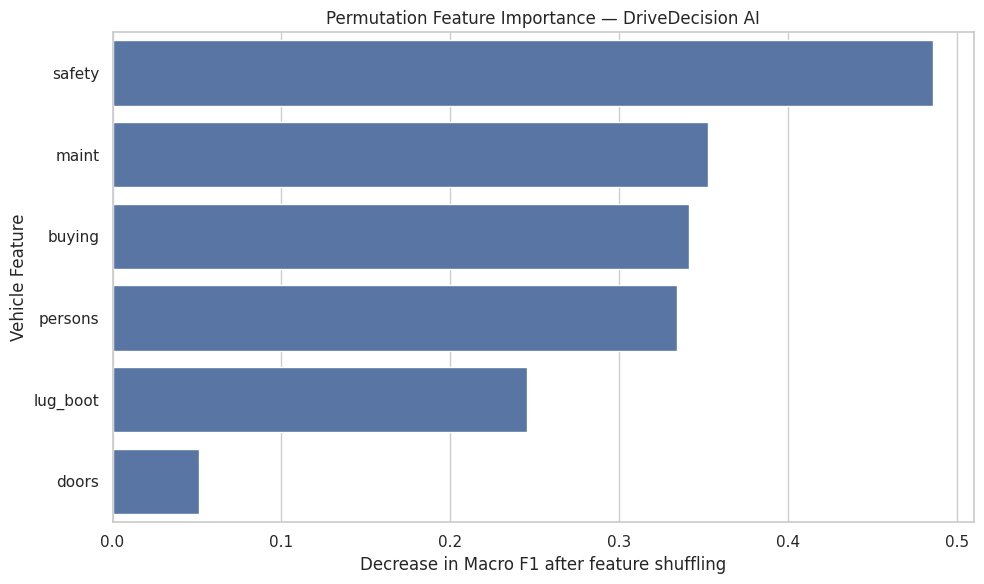


[2/3] Testing different vehicle configurations...

DRIVEDECISION AI — VEHICLE EVALUATION

INPUT CONFIGURATION
buying maint doors persons lug_boot safety
   low   low     2       2    small    low

PREDICTED EVALUATION: UNACC

MODEL PROBABILITIES
acc            : 0.00%
good           : 0.00%
unacc          : 100.00%
vgood          : 0.00%

Note: This is a prediction based on the UCI dataset's
historical evaluation labels, not a real-world safety
certification or personalised purchase recommendation.

DRIVEDECISION AI — VEHICLE EVALUATION

INPUT CONFIGURATION
buying maint doors persons lug_boot safety
 vhigh vhigh     4       4      big   high

PREDICTED EVALUATION: UNACC

MODEL PROBABILITIES
acc            : 5.00%
good           : 0.00%
unacc          : 95.00%
vgood          : 0.00%

Note: This is a prediction based on the UCI dataset's
historical evaluation labels, not a real-world safety
certification or personalised purchase recommendation.

DRIVEDECISION AI — VEHICLE EVALUATION

IN

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


DRIVEDECISION AI — FINAL ENHANCEMENTS COMPLETE


In [3]:


import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.inspection import permutation_importance

print("=" * 60)
print("DRIVEDECISION AI — FINAL QUALITY CHECK")
print("=" * 60)

# 1. PERMUTATION FEATURE IMPORTANCE
# Measures how much model performance changes when a feature
# is shuffled. This works with the original input columns.

print("\n[1/3] Calculating permutation importance...")

perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values("Importance_Mean", ascending=False)

print(perm_df.to_string(index=False))

perm_df.to_csv(
    PROJECT / "outputs/reports/permutation_importance.csv",
    index=False
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=perm_df,
    x="Importance_Mean",
    y="Feature"
)
plt.title("Permutation Feature Importance — DriveDecision AI")
plt.xlabel("Decrease in Macro F1 after feature shuffling")
plt.ylabel("Vehicle Feature")
plt.tight_layout()

plt.savefig(
    PROJECT / "outputs/visualizations/permutation_importance.png",
    dpi=200
)
plt.show()


# 2. VEHICLE CONFIGURATION TEST SUITE

print("\n[2/3] Testing different vehicle configurations...")

test_cases = [
    {
        "Test": "Budget / Low Safety",
        "buying": "low",
        "maint": "low",
        "doors": "2",
        "persons": "2",
        "lug_boot": "small",
        "safety": "low"
    },
    {
        "Test": "High Cost / High Safety",
        "buying": "vhigh",
        "maint": "vhigh",
        "doors": "4",
        "persons": "4",
        "lug_boot": "big",
        "safety": "high"
    },
    {
        "Test": "Family Configuration",
        "buying": "med",
        "maint": "med",
        "doors": "4",
        "persons": "more",
        "lug_boot": "big",
        "safety": "high"
    },
    {
        "Test": "Small City Configuration",
        "buying": "low",
        "maint": "low",
        "doors": "2",
        "persons": "2",
        "lug_boot": "small",
        "safety": "med"
    },
    {
        "Test": "Balanced Configuration",
        "buying": "med",
        "maint": "med",
        "doors": "3",
        "persons": "4",
        "lug_boot": "med",
        "safety": "high"
    }
]

test_results = []

for case in test_cases:

    name = case.pop("Test")

    result = evaluate_vehicle(**case)

    test_results.append({
        "Scenario": name,
        **case,
        "Predicted_Evaluation": result["prediction"]
    })

    case["Test"] = name

test_df = pd.DataFrame(test_results)

print("\nPREDICTION TEST RESULTS")
print(test_df.to_string(index=False))

test_df.to_csv(
    PROJECT / "outputs/reports/prediction_test_suite.csv",
    index=False
)


# 3. FINAL PROJECT VALIDATION

print("\n[3/3] Validating project files...")

required_files = [
    PROJECT / "README.md",
    PROJECT / "requirements.txt",
    PROJECT / "data/car_evaluation_raw.csv",
    PROJECT / "data/car_evaluation_clean.csv",
    PROJECT / "models/vehicle_classifier.pkl",
    PROJECT / "outputs/reports/model_comparison.csv",
    PROJECT / "outputs/reports/classification_report.csv",
    PROJECT / "outputs/reports/project_summary.json",
    PROJECT / "outputs/reports/permutation_importance.csv",
    PROJECT / "outputs/reports/prediction_test_suite.csv",
    PROJECT / "outputs/visualizations/confusion_matrix.png",
    PROJECT / "outputs/visualizations/feature_importance.png"
]

validation = []

for file in required_files:
    validation.append({
        "File": str(file.relative_to(PROJECT)),
        "Exists": file.exists(),
        "Size_KB": round(file.stat().st_size / 1024, 2)
        if file.exists() else 0
    })

validation_df = pd.DataFrame(validation)

print(validation_df.to_string(index=False))

validation_df.to_csv(
    PROJECT / "outputs/reports/file_validation.csv",
    index=False
)

# Save final project summary
final_summary_path = (
    PROJECT / "outputs/reports/final_project_status.json"
)

final_status = {
    "project": "DriveDecision AI",
    "status": (
        "READY_FOR_GITHUB"
        if validation_df["Exists"].all()
        else "CHECK_MISSING_FILES"
    ),
    "selected_model": best_name,
    "test_accuracy": float(
        results_df.iloc[0]["Accuracy"]
    ),
    "test_macro_f1": float(
        results_df.iloc[0]["F1_Macro"]
    ),
    "all_required_files_present": bool(
        validation_df["Exists"].all()
    )
}

with open(final_summary_path, "w") as f:
    json.dump(final_status, f, indent=4)

print("\nFINAL STATUS:", final_status["status"])

# Rebuild updated ZIP
import os
import shutil

zip_path = "/content/DriveDecision-AI.zip"

if os.path.exists(zip_path):
    os.remove(zip_path)

shutil.make_archive(
    "/content/DriveDecision-AI",
    "zip",
    root_dir=PROJECT.parent,
    base_dir=PROJECT.name
)

print("\nUpdated ZIP:", zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("ZIP saved at:", zip_path)

print("\nDRIVEDECISION AI — FINAL ENHANCEMENTS COMPLETE")


DRIVEDECISION AI — FINAL QUALITY CHECK

[1/3] Calculating permutation importance...
 Feature  Importance_Mean  Importance_Std
  safety         0.485547        0.040060
   maint         0.352351        0.040978
  buying         0.341190        0.030655
 persons         0.333851        0.030571
lug_boot         0.245578        0.045939
   doors         0.051081        0.026343


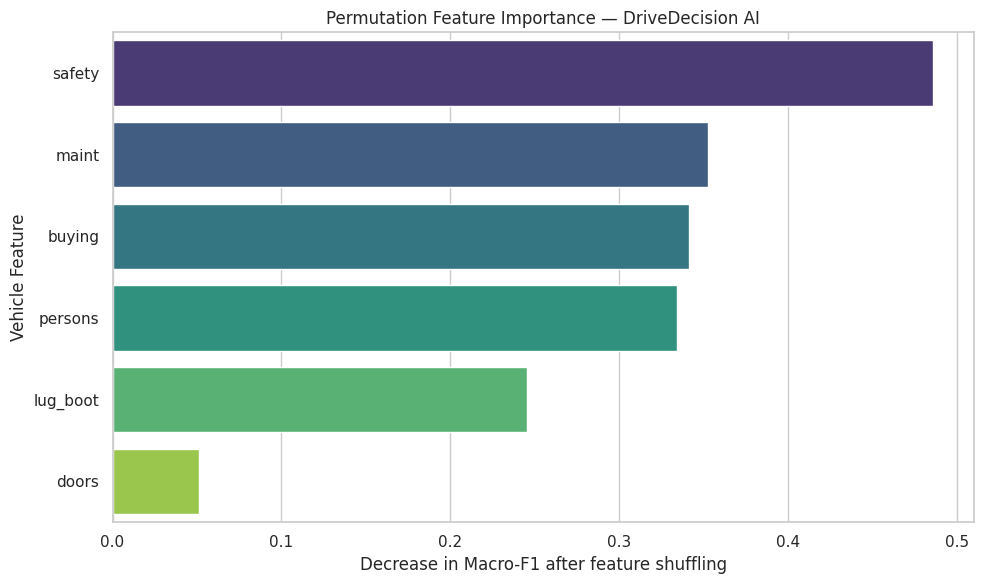


[2/3] Testing different vehicle configurations...

DRIVEDECISION AI — VEHICLE EVALUATION

INPUT CONFIGURATION
buying maint doors persons lug_boot safety
   low   low     2       2    small    low

PREDICTED EVALUATION: UNACC

MODEL PROBABILITIES
acc            : 0.00%
good           : 0.00%
unacc          : 100.00%
vgood          : 0.00%

Note: This is a prediction based on the UCI dataset's
historical evaluation labels, not a real-world safety
certification or personalised purchase recommendation.

DRIVEDECISION AI — VEHICLE EVALUATION

INPUT CONFIGURATION
buying maint doors persons lug_boot safety
 vhigh vhigh     4       4      big   high

PREDICTED EVALUATION: UNACC

MODEL PROBABILITIES
acc            : 5.00%
good           : 0.00%
unacc          : 95.00%
vgood          : 0.00%

Note: This is a prediction based on the UCI dataset's
historical evaluation labels, not a real-world safety
certification or personalised purchase recommendation.

DRIVEDECISION AI — VEHICLE EVALUATION

IN

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


DRIVEDECISION AI — FINAL ENHANCEMENTS COMPLETE


In [4]:
import json
import os
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance

print("=" * 60)
print("DRIVEDECISION AI — FINAL QUALITY CHECK")
print("=" * 60)

# ------------------------------------------------------------------
# 1. PERMUTATION FEATURE IMPORTANCE
# ------------------------------------------------------------------
print("\n[1/3] Calculating permutation importance...")

perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_df = (
    pd.DataFrame({
        "Feature": X_test.columns,
        "Importance_Mean": perm.importances_mean,
        "Importance_Std":  perm.importances_std
    })
    .sort_values("Importance_Mean", ascending=False)
    .reset_index(drop=True)
)

print(perm_df.to_string(index=False))

(PROJECT / "outputs/reports").mkdir(parents=True, exist_ok=True)
(PROJECT / "outputs/visualizations").mkdir(parents=True, exist_ok=True)

perm_df.to_csv(
    PROJECT / "outputs/reports/permutation_importance.csv",
    index=False
)

plt.figure(figsize=(10, 6))
sns.barplot(data=perm_df, x="Importance_Mean", y="Feature", palette="viridis")
plt.title("Permutation Feature Importance — DriveDecision AI")
plt.xlabel("Decrease in Macro-F1 after feature shuffling")
plt.ylabel("Vehicle Feature")
plt.tight_layout()
plt.savefig(
    PROJECT / "outputs/visualizations/permutation_importance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------------
# 2. VEHICLE CONFIGURATION TEST SUITE
# ------------------------------------------------------------------
print("\n[2/3] Testing different vehicle configurations...")

test_cases = [
    {
        "Test": "Budget / Low Safety",
        "buying": "low", "maint": "low", "doors": "2",
        "persons": "2", "lug_boot": "small", "safety": "low"
    },
    {
        "Test": "High Cost / High Safety",
        "buying": "vhigh", "maint": "vhigh", "doors": "4",
        "persons": "4", "lug_boot": "big", "safety": "high"
    },
    {
        "Test": "Family Configuration",
        "buying": "med", "maint": "med", "doors": "4",
        "persons": "more", "lug_boot": "big", "safety": "high"
    },
    {
        "Test": "Small City Configuration",
        "buying": "low", "maint": "low", "doors": "2",
        "persons": "2", "lug_boot": "small", "safety": "med"
    },
    {
        "Test": "Balanced Configuration",
        "buying": "med", "maint": "med", "doors": "3",
        "persons": "4", "lug_boot": "med", "safety": "high"
    },
]

test_results = []
for case in test_cases:
    # Keep original dict intact – never mutate the source list
    payload = {k: v for k, v in case.items() if k != "Test"}
    result  = evaluate_vehicle(**payload)

    test_results.append({
        "Scenario": case["Test"],
        **payload,
        "Predicted_Evaluation": result["prediction"]
    })

test_df = pd.DataFrame(test_results)
print("\nPREDICTION TEST RESULTS")
print(test_df.to_string(index=False))

test_df.to_csv(
    PROJECT / "outputs/reports/prediction_test_suite.csv",
    index=False
)

# ------------------------------------------------------------------
# 3. FINAL PROJECT VALIDATION
# ------------------------------------------------------------------
print("\n[3/3] Validating project files...")

required_files = [
    PROJECT / "README.md",
    PROJECT / "requirements.txt",
    PROJECT / "data/car_evaluation_raw.csv",
    PROJECT / "data/car_evaluation_clean.csv",
    PROJECT / "models/vehicle_classifier.pkl",
    PROJECT / "outputs/reports/model_comparison.csv",
    PROJECT / "outputs/reports/classification_report.csv",
    PROJECT / "outputs/reports/project_summary.json",
    PROJECT / "outputs/reports/permutation_importance.csv",
    PROJECT / "outputs/reports/prediction_test_suite.csv",
    PROJECT / "outputs/visualizations/confusion_matrix.png",
    PROJECT / "outputs/visualizations/feature_importance.png",
    PROJECT / "outputs/visualizations/permutation_importance.png",   # newly created
]

validation = []
for f in required_files:
    exists = f.exists()
    size_kb = round(f.stat().st_size / 1024, 2) if exists else 0.0
    validation.append({
        "File": str(f.relative_to(PROJECT)),
        "Exists": exists,
        "Size_KB": size_kb
    })

validation_df = pd.DataFrame(validation)
print(validation_df.to_string(index=False))

validation_df.to_csv(
    PROJECT / "outputs/reports/file_validation.csv",
    index=False
)

# ------------------------------------------------------------------
# Final status JSON
# ------------------------------------------------------------------
# Safer extraction of the best model metrics
best_row = results_df.loc[results_df["Model"] == best_name].iloc[0]

final_status = {
    "project": "DriveDecision AI",
    "status": (
        "READY_FOR_GITHUB"
        if validation_df["Exists"].all()
        else "CHECK_MISSING_FILES"
    ),
    "selected_model": best_name,
    "test_accuracy": float(best_row["Accuracy"]),
    "test_macro_f1": float(best_row["F1_Macro"]),
    "all_required_files_present": bool(validation_df["Exists"].all()),
    "permutation_top_feature": perm_df.iloc[0]["Feature"],
}

final_summary_path = PROJECT / "outputs/reports/final_project_status.json"
with open(final_summary_path, "w") as f:
    json.dump(final_status, f, indent=4)

print("\nFINAL STATUS:", final_status["status"])
print("Top permutation feature:", final_status["permutation_top_feature"])

# ------------------------------------------------------------------
# Rebuild ZIP (works both in Colab and locally)
# ------------------------------------------------------------------
zip_base = Path("/content") if Path("/content").exists() else PROJECT.parent
zip_path = zip_base / "DriveDecision-AI.zip"

if zip_path.exists():
    zip_path.unlink()

shutil.make_archive(
    str(zip_path.with_suffix("")),          # without .zip
    "zip",
    root_dir=PROJECT.parent,
    base_dir=PROJECT.name
)

print("\nUpdated ZIP:", zip_path)

# Optional Colab download
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    print("ZIP ready at:", zip_path)

print("\nDRIVEDECISION AI — FINAL ENHANCEMENTS COMPLETE")